<a href="https://colab.research.google.com/github/arkaanrobbani09/Sentiment-Analysis/blob/main/sentiment_analysis_fl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install textstat
!pip install kagglehub
!pip install tensorflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 102.8 MB/s eta 0:00:00


In [ ]:
#Importing Libraries

import pandas as pd
import kagglehub
import os
import numpy as np
import matplotlib.pyplot as plt
import re
import random
from nltk.corpus import opinion_lexicon
import textstat
from sklearn.model_selection import train_test_split
import nltk
from nltk.tokenize import word_tokenize
import string
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

from sklearn.feature_extraction.text import CountVectorizer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Dense, Embedding, LSTM, SpatialDropout1D
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from sklearn.utils import resample
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix,classification_report
import re
import tensorflow as tf
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('opinion_lexicon')
nltk.download('wordnet')
%matplotlib inline

nltk.download('averaged_perceptron_tagger')

nltk.download('punkt')


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package opinion_lexicon to /root/nltk_data...
[nltk_data]   Unzipping corpora/opinion_lexicon.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

<h3> Reading Dataset</h3>

In [ ]:
import kagglehub
import os

path1 = kagglehub.dataset_download("saurabhshahane/twitter-sentiment-dataset")
print("Path to dataset files:", path1)

for file in os.listdir(path1):
    if file.endswith(".csv"):
        full_path = os.path.join(path1, file)
        df = pd.read_csv(full_path)
        print(f"Loaded: {file} | Shape: {df.shape}")

df.head()


100%|██████████| 7.60M/7.60M [00:00<00:00, 35.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/saurabhshahane/twitter-sentiment-dataset/versions/1
Loaded: Twitter_Data.csv | Shape: (162980, 2)


,clean_text,category
0,when modi promised “minimum government maximum...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0


In [ ]:
df.shape

(162980, 2)

<h3> EDA and Text Preprocessing </h3>

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162980 entries, 0 to 162979
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   clean_text  162976 non-null  object 
 1   category    162973 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.5+ MB


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.columns

Index(['clean_text', 'category'], dtype='object')

In [ ]:
df["category"].value_counts()

,count
category,
1.0,72249
0.0,55211
-1.0,35509


In [ ]:
#Displaying first five records
df.head()


,clean_text,category
0,when modi promised “minimum government maximum...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0


In [ ]:
df0 = df[df["category"]==0].sample(30000)
df1 = df[df["category"]==1].sample(30000)
df2 = df[df["category"]==-1].sample(30000)

df_balanced = pd.concat([df0, df1, df2], ignore_index=True)
df_balanced.shape


(90000, 2)

<h2> Visualisation </h2>

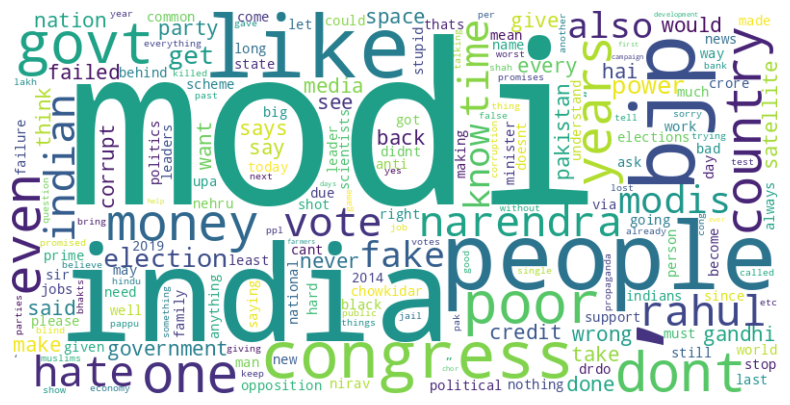

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import nltk
from nltk.corpus import stopwords

# Concatenate all tweets into a single string
all_tweetsp = ' '.join(df2['clean_text'])

# Tokenize the text into individual words
tokensp = nltk.word_tokenize(all_tweetsp)

# Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_tokensp = [word for word in tokensp if word.lower() not in stop_words]

# Get word frequencies
word_freqp = Counter(filtered_tokensp)

# Create a WordCloud object
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freqp)

# Display the word cloud using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.savefig('wordcloud_negative.png')  # ← hapus path /kaggle/working/
plt.show()


In [ ]:
def count_sentiment_words(tweet):

    pos_words = set(opinion_lexicon.positive())
    neg_words = set(opinion_lexicon.negative())
    # Split the tweet into words
    words = tweet.split()
    # Count the number of positive and negative words
    num_pos = len([word for word in words if word in pos_words])
    num_neg = len([word for word in words if word in neg_words])

    # Return the counts as a tuple
    return (num_pos, num_neg)

# function to calculate the Gunning Fog Index of a tweet Readability Measure
def calc_gunning_fog(tweet):
    # Use the textstat library to calculate the Gunning Fog Index
    return textstat.gunning_fog(tweet)

# Define a function to count the number of adverbs and adjectives in a tweet
def count_adj_adv(tweet):
    # Tokenize the tweet into words
    words = word_tokenize(tweet)

    # Use the NLTK part-of-speech (POS) tagger to tag each word with its POS
    pos_tags = nltk.pos_tag(words)

    # Count the number of adverbs and adjectives in the tweet
    adj_count = 0
    adv_count = 0
    for word, pos in pos_tags:
        if pos == 'JJ':
            adj_count += 1
        elif pos == 'RB':
            adv_count += 1

    # Return the counts as a tuple
    return adj_count, adv_count

# Define a function to count the number of names in a tweet
def count_names(tweet):
    name_regex = r'\b[A-Z][a-z]*\b'
    # Use the regular expression to find all matches in the tweet
    name_matches = re.findall(name_regex, tweet)

    # Return the number of matches
    return len(name_matches)

def count_punctuation(tweet):
    return sum([1 for char in tweet if char in string.punctuation])

def count_emoticons(tweet):
    emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)', tweet)
    return len(emoticons)

def count_hashtags(tweet):
    hashtags = re.findall(r'\#\w+', tweet)
    return len(hashtags)

def count_mentions(tweet):
    mentions = re.findall(r'@\w+', tweet)
    return len(mentions)

def feature_engineering(df):
  df["length_tweet"] = [len(i) for i in df["clean_text"].values]
  df["words_tweet"] = [len(i.split()) for i in df["clean_text"].values]
  #df[['num_pos_words', 'num_neg_words']] = df['clean_text'].apply(count_sentiment_words).apply(pd.Series)
  df['gunning_fog'] = df['clean_text'].apply(calc_gunning_fog)
  df[['adj_count', 'adv_count']] = df['clean_text'].apply(count_adj_adv).apply(pd.Series)
  df['name_count'] = df['clean_text'].apply(count_names)
  df['clean_text'] = df['clean_text'].apply(lambda x: x.lower())
  df['punctuation_count'] = df['clean_text'].apply(count_punctuation)
  df['emoticon_count'] = df['clean_text'].apply(count_emoticons)
  df['hashtag_count'] = df['clean_text'].apply(count_hashtags)
  df['mention_count'] = df['clean_text'].apply(count_mentions)

  return df

df_balanced = feature_engineering(df_balanced)


<>:52: SyntaxWarning: invalid escape sequence '\)'
<>:52: SyntaxWarning: invalid escape sequence '\)'
/tmp/ipykernel_3462/3550716836.py:52: SyntaxWarning: invalid escape sequence '\)'
  emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)', tweet)


In [ ]:
df_balanced.to_csv("FE_Balanced_Twitter_Data.csv", index=False)

In [ ]:
import kagglehub
import os

path2 = kagglehub.dataset_download("varunsampathkumar/febalancedtwitterdata")
print("Path to dataset files:", path2)

for file in os.listdir(path2):
    if file.endswith(".csv"):
        full_path = os.path.join(path2, file)
        df_balanced = pd.read_csv(full_path)
        print(f"Loaded: {file} | Shape: {df_balanced.shape}")

df_balanced.head(1)


100%|██████████| 5.32M/5.32M [00:00<00:00, 63.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/varunsampathkumar/febalancedtwitterdata/versions/1


Loaded: FE_Balanced_Twitter_Data.csv | Shape: (90000, 13)


,Unnamed: 0,clean_text,category,length_tweet,words_tweet,gunning_fog,adj_count,adv_count,name_count,punctuation_count,emoticon_count,hashtag_count,mention_count
0,0,mission shakti space ‘not directed against any...,0.0,79,12,8.13,1,1,0,0,0,0,0


In [ ]:
cols = list(set(df_balanced.columns) - {"category"})
# Remove 'clean_text' from cols to get purely numerical columns
numeric_feature_cols = [col for col in cols if col != "clean_text"]

X_text_df = df_balanced["clean_text"]
X_numeric_df = df_balanced[numeric_feature_cols] # This will contain all numerical features

y = df_balanced["category"]

max_fatures = 1000 # This is vocabulary size for text
tokenizer = Tokenizer(num_words=max_fatures, split=' ')
tokenizer.fit_on_texts(X_text_df.values)
X_text = tokenizer.texts_to_sequences(X_text_df.values)
X_text = pad_sequences(X_text) # X_text is now (num_samples, max_text_sequence_length)
TEXT_INPUT_SEQUENCE_LENGTH = X_text.shape[1]

# Convert numerical features to numpy array
X_numeric = X_numeric_df.values
NUMERICAL_FEATURES_COUNT = X_numeric.shape[1]

print(f"Shape of X_text (for embedding): {X_text.shape}")
print(f"Shape of X_numeric (for other features): {X_numeric.shape}")
print("First 2 rows of X_text:")
print(X_text[:2])
print("First 2 rows of X_numeric:")
print(X_numeric[:2])


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 170, 254,  83,
         54,  53,  84,  32,   1, 107],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 606,   3,  83,
         84, 325, 390, 378, 108, 258]], dtype=int32)

In [ ]:
X.shape

(90000, 45)

In [ ]:
type(X)

numpy.ndarray

In [ ]:
for i in set(cols)-{"clean_text"}:
    X = np.hstack((X, X_df[i].values.reshape(-1,1)))

X.shape


(90000, 56)

In [ ]:
y = pd.get_dummies(y).values

y.shape


(90000, 3)

In [ ]:
from sklearn.model_selection import train_test_split

# First, create 1D labels for stratification
y_labels = df_balanced["category"].values # Original category labels before one-hot encoding

# Split all data (text, numerical, and original labels) using the 1D labels for stratification
X_text_train_raw, X_text_test_raw, X_numeric_train_raw, X_numeric_test_raw, y_train_labels, y_test_labels = train_test_split(
    X_text, X_numeric, y_labels, test_size=0.2, random_state=42, stratify=y_labels)

# Convert y_train_labels and y_test_labels back to one-hot encoding for the model
y_train = pd.get_dummies(y_train_labels).values
y_test = pd.get_dummies(y_test_labels).values

# Combine inputs for Keras functional API model as a list of arrays
X_train = [X_text_train_raw, X_numeric_train_raw]
X_test = [X_text_test_raw, X_numeric_test_raw]

print(f"X_train_text shape: {X_train[0].shape}, X_train_numeric shape: {X_train[1].shape}, y_train shape: {y_train.shape}")
print(f"X_test_text shape: {X_test[0].shape}, X_test_numeric shape: {X_test[1].shape}, y_test shape: {y_test.shape}")


(72000, 56) (72000, 3)
(18000, 56) (18000, 3)


<h2> Centralized Model Training </h2>

In [ ]:
y_train_label_encoded = pd.DataFrame(y_train).idxmax(axis=1).values
y_test_label_encoded = pd.DataFrame(y_test).idxmax(axis=1).values

# Check if GPU is available
if tf.test.is_gpu_available():
    # Set memory growth to True to allocate GPU memory only when needed
    physical_devices = tf.config.experimental.list_physical_devices('GPU')
    tf.config.experimental.set_memory_growth(physical_devices[0], True)


Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


<h3> LSTM Model</h3>

In [ ]:
from keras.models import Model
from keras.layers import Input, Embedding, LSTM, Dense, Dropout, BatchNormalization, Concatenate
from sklearn.metrics import accuracy_score

embed_dim = 128

# Define input for text features
text_input = Input(shape=(TEXT_INPUT_SEQUENCE_LENGTH,), name='text_input')
embedding_layer = Embedding(max_fatures, embed_dim, input_length=TEXT_INPUT_SEQUENCE_LENGTH)(text_input)
lstm_layer = LSTM(64)(embedding_layer)
dropout_text = Dropout(0.45)(lstm_layer)
batch_norm_text = BatchNormalization()(dropout_text)

# Define input for numerical features
numerical_input = Input(shape=(NUMERICAL_FEATURES_COUNT,), name='numerical_input')
batch_norm_numeric = BatchNormalization()(numerical_input) # Apply batch norm to numerical features as well

# Concatenate the outputs of text and numerical branches
merged = Concatenate()([batch_norm_text, batch_norm_numeric])

# Add Dense layers for the combined features
dense1 = Dense(16, activation='relu')(merged)
batch_norm_dense1 = BatchNormalization()(dense1)
output = Dense(3, activation='softmax')(batch_norm_dense1)

model = Model(inputs=[text_input, numerical_input], outputs=output)
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
batch_size =  256
epoch = 100
test_acc_lstm = []
train_acc_lstm = []
for i in range(epoch):
    model.fit(X_train, y_train, epochs = 1, batch_size=batch_size, verbose = 1)
    Y_test_pred =np.argmax(model.predict(X_test), axis=-1)
    test_acc_lstm.append(accuracy_score(y_test_label_encoded,Y_test_pred))

    Y_train_pred =np.argmax(model.predict(X_train), axis=-1)
    train_acc_lstm.append(accuracy_score(y_train_label_encoded,Y_train_pred))


InvalidArgumentError: Graph execution error:

Detected at node sequential_1/embedding_1/GatherV2 defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.12/dist-packages/traitlets/config/application.py", line 992, in launch_instance

  File "/usr/local/lib/python3.12/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.12/dist-packages/tornado/platform/asyncio.py", line 211, in start

  File "/usr/lib/python3.12/asyncio/base_events.py", line 645, in run_forever

  File "/usr/lib/python3.12/asyncio/base_events.py", line 1999, in _run_once

  File "/usr/lib/python3.12/asyncio/events.py", line 88, in _run

  File "/usr/local/lib/python3.12/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_queue

  File "/usr/local/lib/python3.12/

In [ ]:
import matplotlib.pyplot as plt

plt.plot(test_acc_lstm,label="Test Accuracy")
plt.plot(train_acc_lstm,label="Train Accuracy")
plt.title("Accuracy vs epochs LSTM")
plt.legend()
plt.xlabel("epochs")
plt.ylabel("Accuracy")
plt.show()

Y_pred =np.argmax(model.predict(X_test), axis=-1)

print(classification_report(y_test_label_encoded,Y_pred))


In [ ]:
#BiLSTM + CNN
from keras.models import Sequential
from sklearn.metrics import accuracy_score
from keras.layers import Embedding, Conv1D,MaxPooling1D, AveragePooling1D, Bidirectional, LSTM, Dense, Dropout, BatchNormalization

embed_dim = 128
lstm_out = 196

model = Sequential()
model.add(Embedding(max_fatures, embed_dim,input_length = X.shape[1]))
model.add(Conv1D(filters=256, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling1D(pool_size=2))
model.add(Bidirectional(LSTM(128)))
model.add(Dense(3, activation='softmax'))
model.compile(loss = 'categorical_crossentropy', optimizer='Nadam',metrics = ['accuracy'])
model.summary()


In [ ]:
batch_size =  256
epoch = 100
test_acc_bilstmcnn = []
train_acc_bilstmcnn = []
for i in range(epoch):
    model.fit(X_train, y_train, epochs = 1, batch_size=batch_size, verbose = 1)
    Y_test_pred =np.argmax(model.predict(X_test), axis=-1)
    test_acc_bilstmcnn.append(accuracy_score(y_test_label_encoded,Y_test_pred))

    Y_train_pred =np.argmax(model.predict(X_train), axis=-1)
    train_acc_bilstmcnn.append(accuracy_score(y_train_label_encoded,Y_train_pred))


In [ ]:
import matplotlib.pyplot as plt

plt.plot(test_acc_bilstmcnn,label="Test Accuracy")
plt.plot(train_acc_bilstmcnn,label="Train Accuracy")
plt.title("Accuracy vs epochs BiLSTM+CNN")
plt.legend()
plt.xlabel("epochs")
plt.ylabel("Accuracy")
plt.show()

Y_pred =np.argmax(model.predict(X_test), axis=-1)

print(classification_report(y_test_label_encoded,Y_pred))


In [ ]:
model1 = Sequential()
model1.add(Embedding(max_fatures, embed_dim,input_length = X.shape[1]))
model1.add(Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'))
model1.add(MaxPooling1D(pool_size=2))
model1.add(Bidirectional(LSTM(32)))
model1.add(Dropout(0.2))
model1.add(Dense(3, activation='softmax'))
model1.compile(loss = 'categorical_crossentropy', optimizer='Nadam',metrics = ['accuracy'])
model1.summary()


In [ ]:
batch_size =  256
epoch = 100
test_acc_bilstm = []
train_acc_bilstm = []
for i in range(epoch):
    model1.fit(X_train, y_train, epochs = 1, batch_size=batch_size, verbose = 1)
    Y_test_pred =np.argmax(model1.predict(X_test), axis=-1)
    test_acc_bilstm.append(accuracy_score(y_test_label_encoded,Y_test_pred))

    Y_train_pred =np.argmax(model1.predict(X_train), axis=-1)
    train_acc_bilstm.append(accuracy_score(y_train_label_encoded,Y_train_pred))


In [ ]:
import matplotlib.pyplot as plt

plt.plot(test_acc_bilstm,label="Test Accuracy")
plt.plot(train_acc_bilstm,label="Train Accuracy")
plt.title("Accuracy vs epochs BiLSTM")
plt.legend()
plt.xlabel("epochs")
plt.ylabel("Accuracy")
plt.show()

Y_pred =np.argmax(model.predict(X_test), axis=-1)

print(classification_report(y_test_label_encoded,Y_pred))


<hr>
<hr>
<hr>
<h2> Federated Learning Setup </h2>

In [ ]:
from tensorflow.keras import backend as K
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, BatchNormalization, Concatenate

def create_clients(X_text_data, X_numeric_data, label_list, num_clients=3, initial='clients'):
    """
    return: a dictionary with keys clients' names and value as
            data shards - tuple of (text_data, numerical_data, label).
    args:
        X_text_data: numpy array of text features
        X_numeric_data: numpy array of numerical features
        label_list: list of binarized labels for each data
        num_clients: number of federated members (clients)
        initial: the clients' name prefix, e.g, clients_1
    """
    import random

    # create a list of client names
    client_names = ['{}_{}'.format(initial, i+1) for i in range(num_clients)]

    # Combine data from all sources (text, numerical, labels)
    # Each item in 'data' will be (text_sample, numerical_sample, label_sample)
    data = list(zip(X_text_data, X_numeric_data, label_list))
    random.shuffle(data)

    # shard data and place at each client
    size = len(data) // num_clients
    shards = [data[i:i + size] for i in range(0, size * num_clients, size)]

    # number of clients must equal number of shards
    assert(len(shards) == len(client_names))

    return {client_names[i]: shards[i] for i in range(len(client_names))}

class FLModel:
  def build(self):
    embed_dim = 128

    # Define input for text features
    text_input = Input(shape=(TEXT_INPUT_SEQUENCE_LENGTH,), name='text_input_fl')
    embedding_layer = Embedding(max_fatures, embed_dim, input_length=TEXT_INPUT_SEQUENCE_LENGTH)(text_input)
    lstm_layer = LSTM(64)(embedding_layer)
    dropout_text = Dropout(0.45)(lstm_layer)
    batch_norm_text = BatchNormalization()(dropout_text)

    # Define input for numerical features
    numerical_input = Input(shape=(NUMERICAL_FEATURES_COUNT,), name='numerical_input_fl')
    batch_norm_numeric = BatchNormalization()(numerical_input)

    # Concatenate the outputs of text and numerical branches
    merged = Concatenate()([batch_norm_text, batch_norm_numeric])

    # Add Dense layers for the combined features
    dense1 = Dense(16, activation='relu')(merged)
    batch_norm_dense1 = BatchNormalization()(dense1)
    output = Dense(3, activation='softmax')(batch_norm_dense1)

    model = Model(inputs=[text_input, numerical_input], outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    #model.summary()

    return model

clients = create_clients(X_train[0], X_train[1], y_train, num_clients=3, initial='client')


In [ ]:
def sum_scaled_weights(scaled_weight_list):
    """Return the sum of the listed scaled weights. This is equivalent to scaled avg of the weights"""
    avg_grad = list()
    # get the average grad across all client gradients
    for grad_list_tuple in zip(*scaled_weight_list):
        layer_mean = tf.math.reduce_sum(grad_list_tuple, axis=0)
        avg_grad.append(layer_mean)

    return avg_grad

def scale_model_weights(weight, n=3):
    """Function for scaling a models weights"""
    weight_final = []
    steps = len(weight)
    scalar = 1/n

    for i in range(steps):
        weight_final.append(scalar * weight[i])
    return weight_final


In [ ]:
comms_round = 20
lr = 0.001
loss = 'categorical_crossentropy'
metrics = ['accuracy']

# initialize global model
smlp_global = FLModel()
global_model = smlp_global.build()

# Build global model with dummy data to initialize weights
import numpy as np
dummy_X_text = np.zeros((1, TEXT_INPUT_SEQUENCE_LENGTH)) # Use correct shape for text input
dummy_X_numeric = np.zeros((1, NUMERICAL_FEATURES_COUNT)) # Use correct shape for numerical input
global_model.predict([dummy_X_text, dummy_X_numeric]) # Predict with list of inputs

global_acc = []
global_loss = 10
noOfClasses = 3

# commence global training loop
while comms_round != 0:

    # get the global model's weights
    global_weights = global_model.get_weights()
    local_weight_list = list()

    client_names = list(clients.keys())
    random.shuffle(client_names)

    print("-----------------Workers Building Up------------------------------")
    for client in client_names:
        smlp_local = FLModel()
        local_model = smlp_local.build()

        optimizer = tf.keras.optimizers.Adam(learning_rate=lr)

        local_model.compile(loss=loss, optimizer=optimizer, metrics=metrics)

        # Initialize local weights with dummy predict first
        local_model.predict([dummy_X_text, dummy_X_numeric]) # Predict with list of inputs
        local_model.set_weights(global_weights)

        df_local = clients[client]
        # Each item in df_local is (text_sample, numerical_sample, label_sample)
        X_local_text = np.array([item[0] for item in df_local])
        X_local_numeric = np.array([item[1] for item in df_local])
        Y_local = np.array([item[2] for item in df_local])

        print(f"X_local_text shape: {X_local_text.shape}, X_local_numeric shape: {X_local_numeric.shape}")
        print(f"Y_local shape: {Y_local.shape}")

        local_model.fit([X_local_text, X_local_numeric], Y_local, epochs=4, verbose=0) # Fit with list of inputs
        scaled_weights = scale_model_weights(local_model.get_weights(), len(clients))
        local_weight_list.append(scaled_weights)

        lYpred = np.argmax(local_model.predict([X_local_text, X_local_numeric]), axis=-1) # Predict with list of inputs
        lY_pred = []
        for i in lYpred:
            temp = [1 if j == i else 0 for j in range(noOfClasses)]
            lY_pred.append(temp)

        cce = tf.keras.losses.CategoricalCrossentropy(from_logits=True)
        llogits = local_model.predict([X_local_text, X_local_numeric]) # Predict with list of inputs
        lloss = cce(Y_local, llogits)
        lacc = accuracy_score(Y_local, lY_pred)
        print('comm_round: {} | Client: {} | Local_acc: {:.3%} | local_loss: {}'.format(
            comms_round, client, lacc, lloss))

        # Simpan weights sebelum clear session
        del local_model
        K.clear_session()

    print("-----------------Workers Building Done------------------------------")

    # Rebuild global model dan restore weights
    average_weights = sum_scaled_weights(local_weight_list)

    smlp_global = FLModel()
    global_model = smlp_global.build()
    global_model.predict([dummy_X_text, dummy_X_numeric])  # Initialize with list of inputs
    global_model.set_weights(average_weights)

    # test global model
    Ypred = np.argmax(global_model.predict(X_test), axis=-1) # Predict with list of inputs
    Y_pred = []
    for i in Ypred:
        temp = [1 if j == i else 0 for j in range(noOfClasses)]
        Y_pred.append(temp)

    cce = tf.keras.losses.CategoricalCrossentropy(from_logits=True)
    logits = global_model.predict(X_test) # Predict with list of inputs
    global_loss = cce(y_test, logits)
    acc = accuracy_score(y_test, Y_pred)
    global_acc.append(acc)
    print('comm_round: {} | global_acc: {:.3%} | global_loss: {}'.format(comms_round, acc, global_loss))
    print("--------------------------------------------------------------------------------------------")
    comms_round -= 1


In [ ]:
import matplotlib.pyplot as plt

plt.plot(global_acc,label="FedAvg")
plt.plot(test_acc_lstm[:len(global_acc)],label="Centralized-LSTM")
plt.title("Accuracy vs epochs")
plt.xlabel("epochs")
plt.ylabel("Test Accuracy")
plt.legend()
plt.show()


In [ ]:
print(classification_report(y_test_label_encoded,Ypred))
